In [62]:
import pandas as pd 
import numpy as np    
import seaborn as sns           
import matplotlib.pyplot as plt   
from pathlib import Path         


In [63]:
data_dir = Path().resolve().parent
file_path = data_dir / "teachpandas" / "sample_drone_flights.csv"

if not file_path.exists():
    raise FileExistsError("Specific file doesn't exist")
df = pd.read_csv(file_path)

if len(set(df.columns)) == len(df.columns):
    df = df.loc[:, df.columns.drop_duplicates()]
    
for col in [col for col in df.columns if "date" in col]:
    df[col] = pd.to_datetime(df[col])

In [64]:
def clean_columns(df):
    dfx = df.copy()
    dfx.columns = dfx.columns.str.strip()
    return dfx 

In [65]:
df_clean = clean_columns(df)
selected_cols = [
    "datetime(utc)",
    "flycState",
    'current(A)',
    "battery_temperature(f)",
    "speed(mph)",
    "voltage(v)",
    "longitude",
    "latitude",
    "time(millisecond)",
]
new_df = df[selected_cols]
df_sorted = new_df.sort_values(by=["datetime(utc)"])

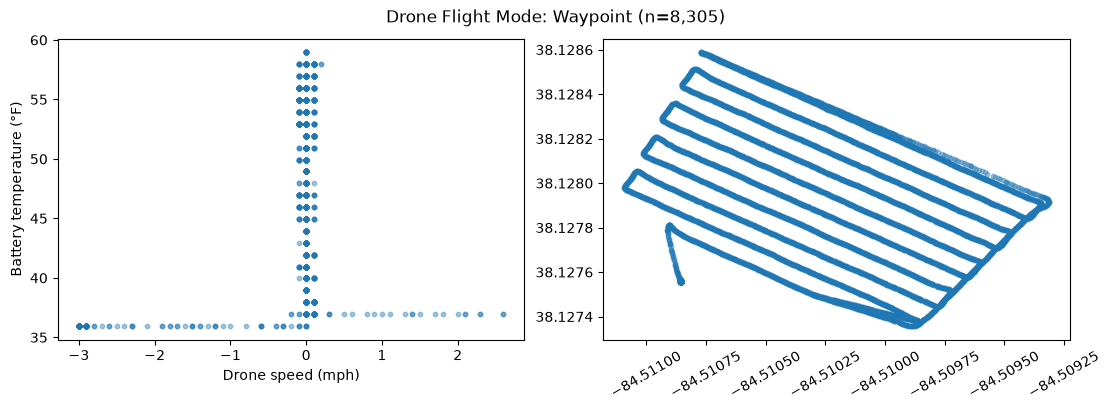

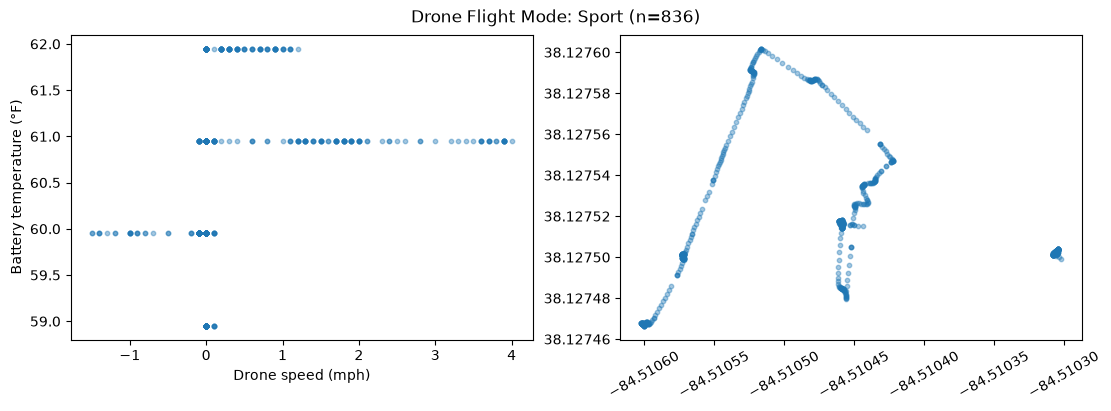

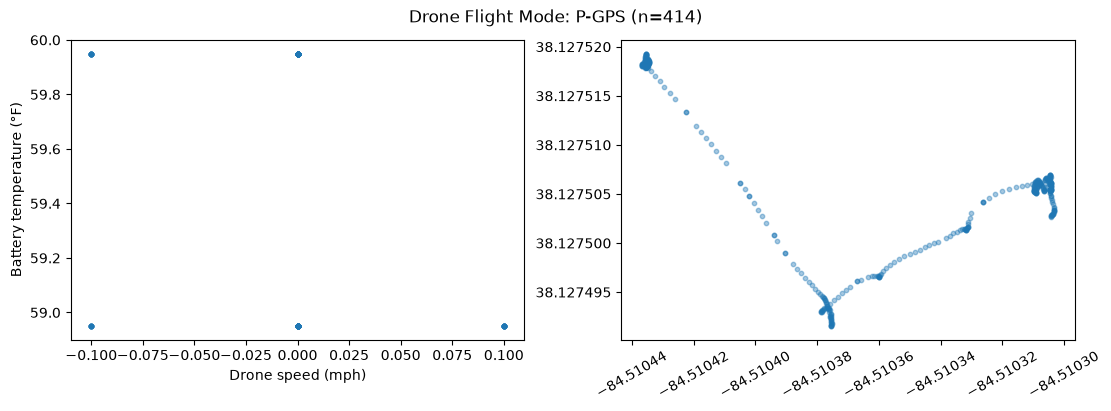

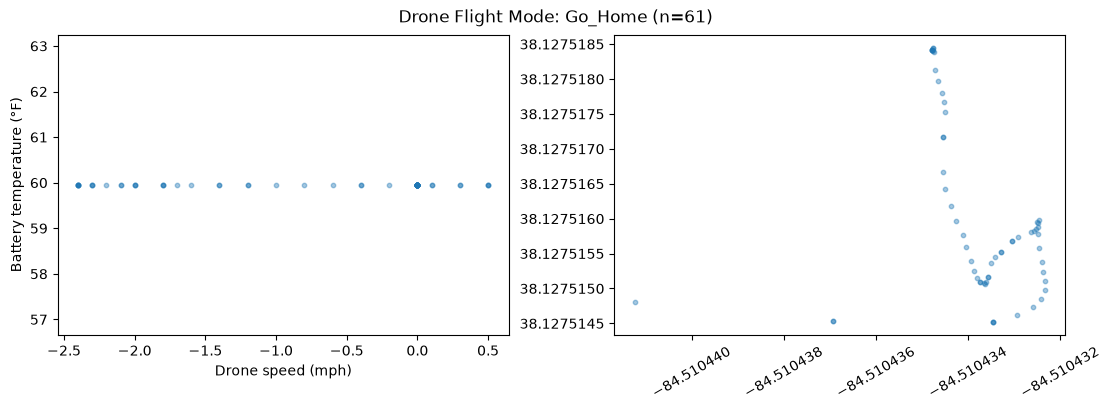

In [75]:
df_plot= df_sorted.select_dtypes(include=["number", "string", "object"])
for flystate, dfx in df_plot.groupby("flycState", sort=False):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

    ax[0].scatter(
        dfx["speed(mph)"],
        dfx["battery_temperature(f)"],
        s=10,
        alpha=0.4,
    )
    ax[0].set(
        xlabel="Drone speed (mph)",
        ylabel="Battery temperature (°F)",
    )

    ax[1].scatter(dfx["longitude"], dfx["latitude"], s=10, alpha=0.4)
    ax[1].tick_params(axis="x", labelrotation=30)
    ax[1].ticklabel_format(style="plain", useOffset=False)

    fig.suptitle(f"Drone Flight Mode: {flystate} (n={len(dfx):,})")

plt.show()

In [88]:
summary = df_plot.groupby("flycState", as_index=False)[["battery_temperature(f)"]].agg(
                        battery_temp_sum = ("battery_temperature(f)", "sum"), 
                        battery_temp_max = ("battery_temperature(f)", "sum"),
                        battery_temp_min = ("battery_temperature(f)", "sum")
                    )

In [76]:
# plot = df_plot.sort_values("time(millisecond)", kind="stable").copy()
# dt_s = plot["time(millisecond)"].diff() / 1_000
# mean_lat = (plot["latitude"] + plot["latitude"].shift()) / 2

# east_m = (
#     plot["longitude"].diff()
#     * 111_320
#     * np.cos(np.deg2rad(mean_lat))
# )
# plot["east_mph"] = (east_m / dt_s.where(dt_s > 0)) * 2.23694

# # Small changes can be GPS jitter. Adjust this threshold for your data.
# threshold_mph = 0.5
# plot["direction"] = np.select(
#     [plot["east_mph"] < -threshold_mph, plot["east_mph"] > threshold_mph],
#     ["West", "East"],
#     default="Near zero",
# )
# plot = plot.dropna(subset=["east_mph"])

# colors = {"West": "tab:blue", "East": "tab:orange", "Near zero": "gray"}
# limit = max(plot["east_mph"].abs().max(), 1)

# for flystate, dfx in plot.groupby("flycState", sort=False):
#     fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

#     for direction, rows in dfx.groupby("direction", sort=False):
#         color = colors[direction]
#         ax[0].scatter(
#             rows["east_mph"], rows["battery_temperature(f)"],
#             color=color, s=10, alpha=0.5,
#         )
#         ax[1].scatter(
#             rows["longitude"], rows["latitude"],
#             color=color, s=10, alpha=0.5, label=direction,
#         )

#     ax[0].axvline(0, color="black", linewidth=0.8)
#     ax[0].set(
#         xlim=(-limit, limit),
#         xlabel="East–west velocity (mph)",
#         ylabel="Battery temperature (°F)",
#     )
#     ax[1].set(xlabel="Longitude", ylabel="Latitude")
#     ax[1].ticklabel_format(style="plain", useOffset=False)
#     ax[1].tick_params(axis="x", labelrotation=30)
#     ax[1].legend()
#     fig.suptitle(f"Drone flight mode: {flystate}")

# plt.show()

In [89]:
from datetime import datetime

today = datetime.today()

print(today)

2026-11-26 00:25:18.390204
